In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# [필수] 'df' 변수가 정의되어 있지 않은 경우를 대비하여 앞선 분석 로직 데이터를 안전하게 로드합니다.
try:
    _ = df
except NameError:
    print("이전 셀의 df 데이터를 새로 가져옵니다...")
    ticker = '005930.KS'
    start_date = '2025-06-01'
    end_date = '2026-10-02'
    df = yf.download(ticker, start=start_date, end=end_date)

    if df.empty or len(df) < 20:
        dates = pd.date_range(start=start_date, end=end_date, freq='B')
        np.random.seed(42)
        price = 75000 + np.cumsum(np.random.normal(0, 1000, len(dates)))
        volume = np.random.randint(10000000, 20000000, len(dates))
        spike_indices = [20, 50, 80, 110, 150]
        for idx in spike_indices: volume[idx] *= 2.5
        df = pd.DataFrame({'Close': price, 'Volume': volume}, index=dates)

    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    # 필요한 파생 변수 계산
    df['Price_Diff'] = df['Close'].diff()
    df['Vol_MA20'] = df['Volume'].rolling(window=20).mean()
    df['Is_Spike'] = df['Volume'] > (df['Vol_MA20'] * 1.5)

# 1. 패닉셀 조건 필터링 (거래량 급증 + 주가 하락)
panic_sell_df = df[(df['Is_Spike'] == True) & (df['Price_Diff'] < 0)].copy()

# 2. 하락률(%) 계산 (전일 종가 대비)
panic_sell_df['Drop_Rate'] = (panic_sell_df['Price_Diff'] / (df['Close'].shift(1))) * 100

# 3. 결과 출력 (날짜, 종가, 거래량, 하락률)
print("===== [Panic Sell 발생일 분석 리포트] =====")
if panic_sell_df.empty:
    print("분석 기간 내 패닉셀 구간이 발견되지 않았습니다.")
else:
    # 보기 좋게 출력하기 위해 인덱스(날짜) 포맷 변경
    report = panic_sell_df[['Close', 'Volume', 'Drop_Rate']].copy()
    report.index = report.index.strftime('%Y-%m-%d')
    print(report)

# 4. 가장 심했던 날 찾기
if not panic_sell_df.empty:
    worst_day = panic_sell_df['Drop_Rate'].idxmin()
    print(f"\n★ 가장 강력한 패닉셀 발생일: {worst_day.strftime('%Y-%m-%d')}")
    print(f"당일 하락률: {panic_sell_df.loc[worst_day, 'Drop_Rate']:.2f}%")

===== [Panic Sell 발생일 분석 리포트] =====
Price               Close    Volume  Drop_Rate
Date                                          
2025-11-05   99796.492188  44843020  -4.099136
2026-01-08  138360.703125  41449329  -1.560301
2026-02-27  215814.812500  51774768  -0.688072
2026-03-03  194482.531250  54879010  -9.884531
2026-03-04  171655.000000  89427954 -11.737574
2026-04-09  203775.265625  42320839  -3.087888
2026-05-12  278692.656250  41211149  -2.276709
2026-07-29  208500.000000  65555523  -5.227273

★ 가장 강력한 패닉셀 발생일: 2026-03-04
당일 하락률: -11.74%


/tmp/ipykernel_547/1933162408.py:11: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(ticker, start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed


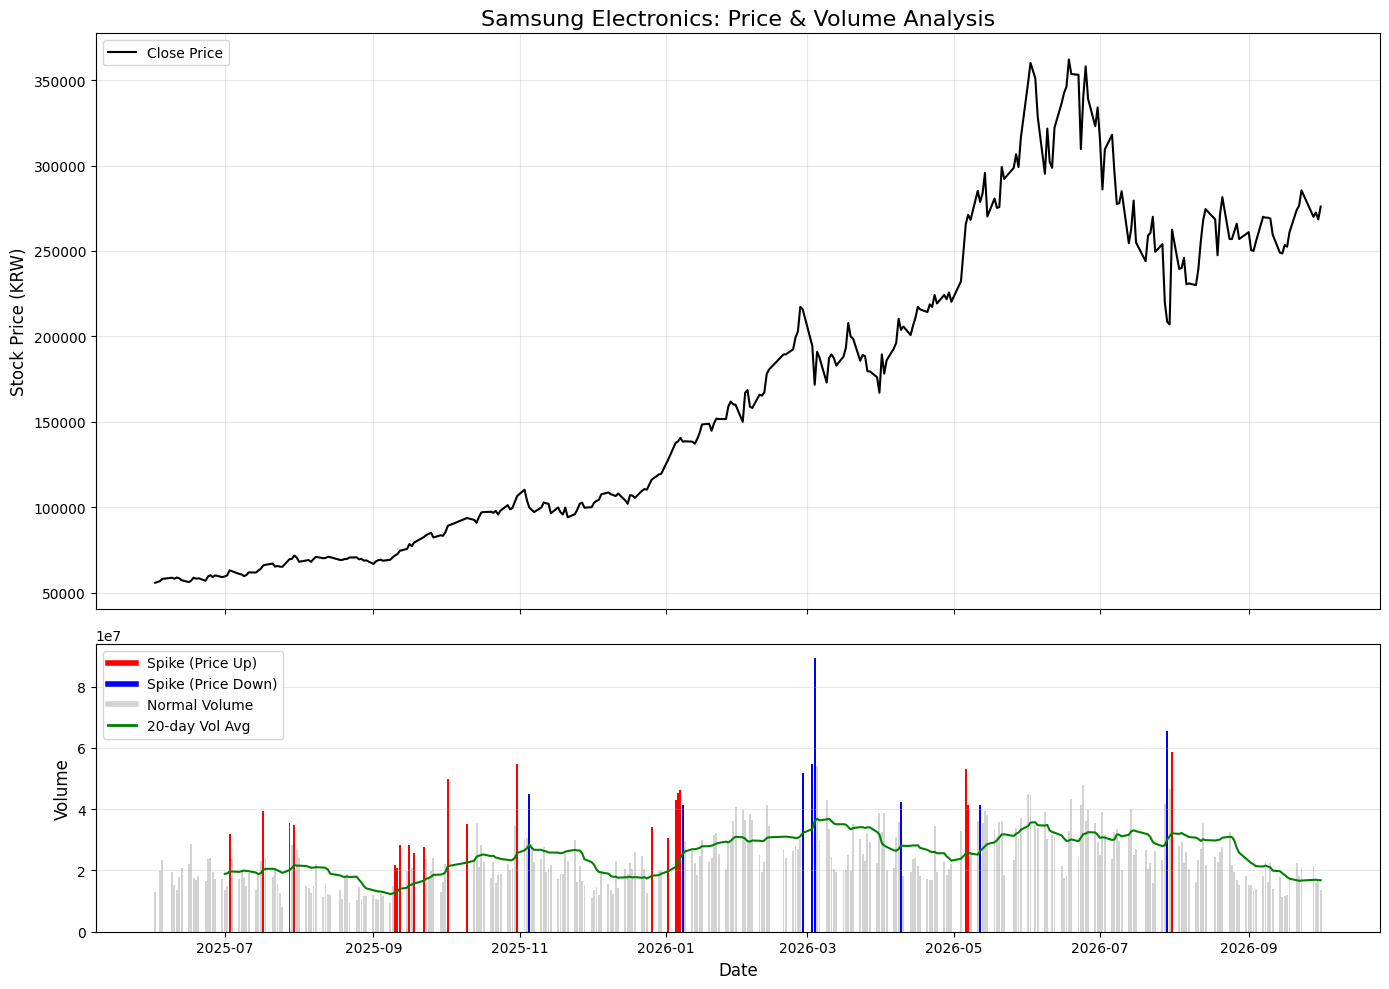

===== Panic Sell Dates (Blue Bars) =====
['2025-11-05', '2026-01-08', '2026-02-27', '2026-03-03', '2026-03-04', '2026-04-09', '2026-05-12', '2026-07-29']


In [ ]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

# 1. 데이터 수집 및 준비
ticker = '005930.KS'
start_date = '2025-06-01'
end_date = '2026-10-02'
df = yf.download(ticker, start=start_date, end=end_date)

# 데이터 부족 시 가상 데이터 생성 (실습용)
if df.empty or len(df) < 20:
    dates = pd.date_range(start=start_date, end=end_date, freq='B')
    np.random.seed(42)
    price = 75000 + np.cumsum(np.random.normal(0, 1000, len(dates)))
    volume = np.random.randint(10000000, 20000000, len(dates))
    spike_indices = [20, 50, 80, 110, 150]
    for idx in spike_indices: volume[idx] *= 2.5
    df = pd.DataFrame({'Close': price, 'Volume': volume}, index=dates)

if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 2. 분석 로직
df['Price_Diff'] = df['Close'].diff()
df['Vol_MA20'] = df['Volume'].rolling(window=20).mean()
df['Is_Spike'] = df['Volume'] > (df['Vol_MA20'] * 1.5)

def set_color(row):
    if row['Is_Spike']:
        return 'red' if row['Price_Diff'] > 0 else 'blue'
    return 'lightgray'

df['Color'] = df.apply(set_color, axis=1)

# 3. 시각화 (서브플롯 구조)
plt.rcParams['axes.unicode_minus'] = False
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True,
                               gridspec_kw={'height_ratios': [2, 1]})

# (1) 상단: 주가 차트 (Price Chart)
ax1.plot(df.index, df['Close'], color='black', linewidth=1.5, label='Close Price')
ax1.set_title("Samsung Electronics: Price & Volume Analysis", fontsize=16)
ax1.set_ylabel("Stock Price (KRW)", fontsize=12)
ax1.grid(True, alpha=0.3)
ax1.legend(loc='upper left')

# (2) 하단: 거래량 차트 (Volume Chart)
ax2.bar(df.index, df['Volume'], color=df['Color'], width=0.8, label='Volume')
ax2.plot(df.index, df['Vol_MA20'], color='green', linewidth=1.5, label='20-day Vol Avg')
ax2.set_ylabel("Volume", fontsize=12)
ax2.set_xlabel("Date", fontsize=12)
ax2.grid(axis='y', alpha=0.3)

# 범례 커스텀
legend_elements = [
    Line2D([0], [0], color='red', lw=4, label='Spike (Price Up)'),
    Line2D([0], [0], color='blue', lw=4, label='Spike (Price Down)'),
    Line2D([0], [0], color='lightgray', lw=4, label='Normal Volume'),
    Line2D([0], [0], color='green', lw=2, label='20-day Vol Avg')
]
ax2.legend(handles=legend_elements, loc='upper left')

plt.tight_layout()
plt.show()

# 4. 패닉셀(파란 막대) 날짜 출력
panic_days = df[(df['Is_Spike'] == True) & (df['Price_Diff'] < 0)]
print("===== Panic Sell Dates (Blue Bars) =====")
print(panic_days.index.strftime('%Y-%m-%d').tolist())

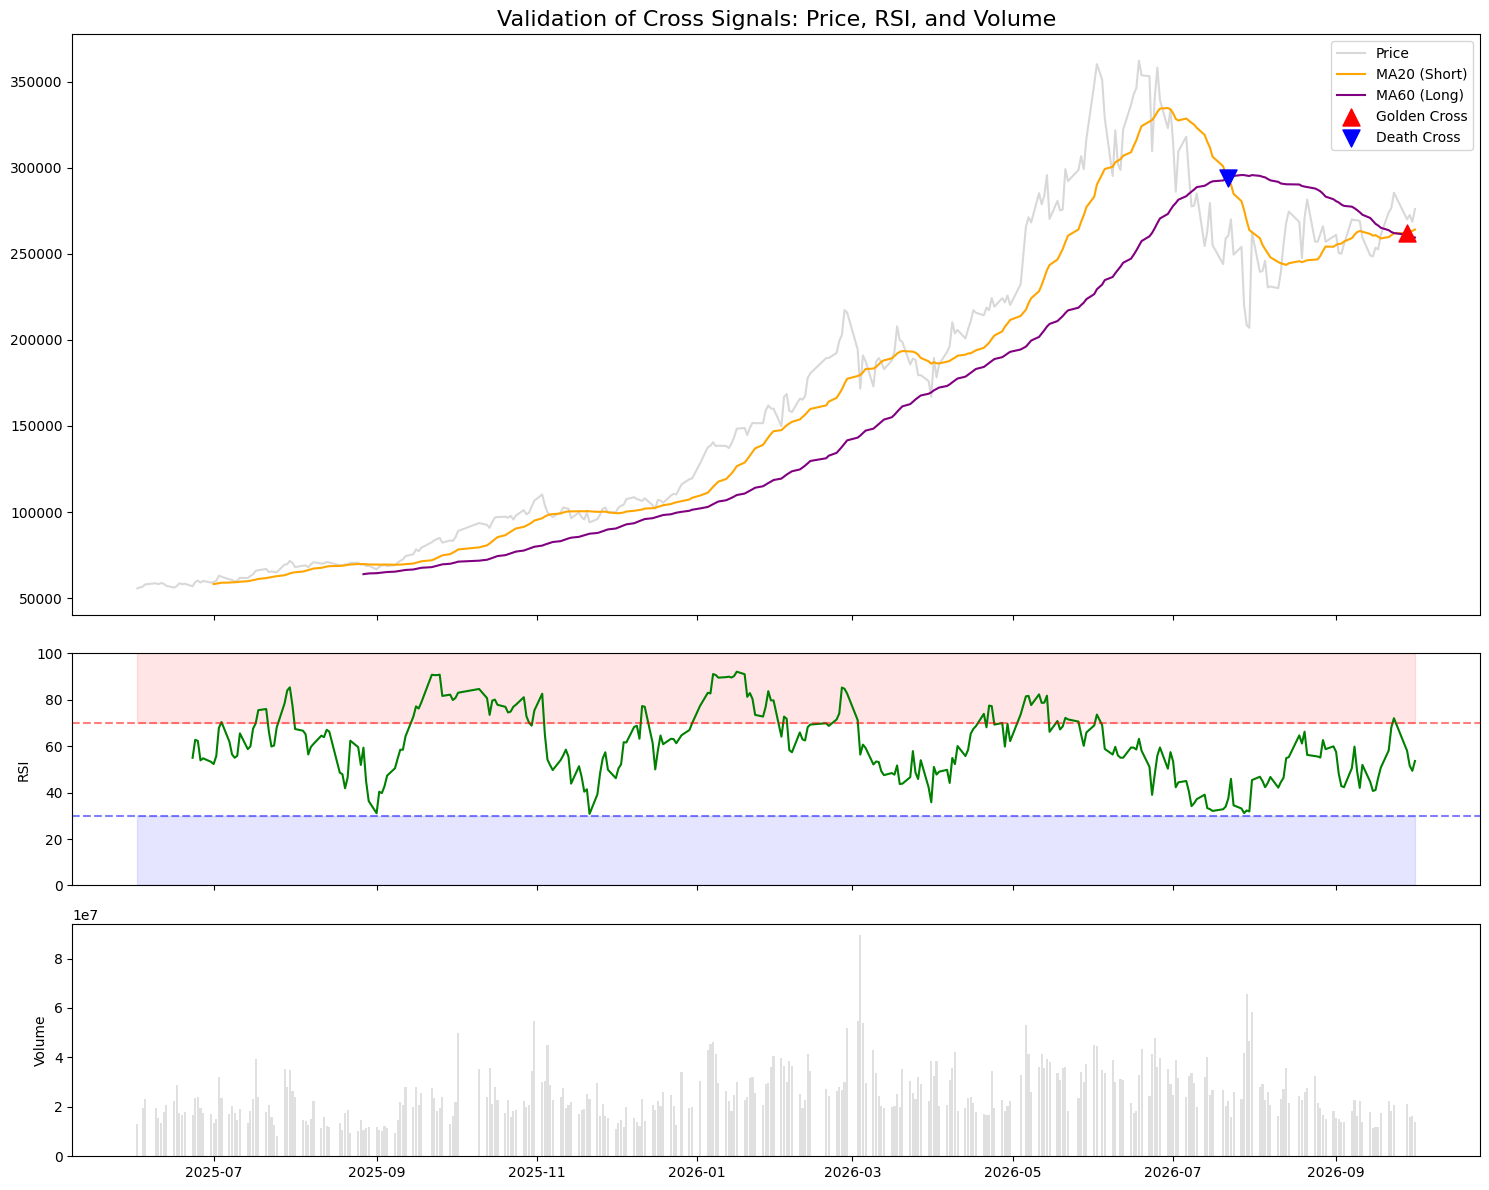

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --- 1. RSI 계산 함수 정의 ---
def calculate_rsi(data, window=14):
    delta = data.diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=window).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=window).mean()
    rs = gain / loss
    return 100 - (100 / (1 + rs))

# --- 2. 지표 계산 ---
df['MA20'] = df['Close'].rolling(window=20).mean()
df['MA60'] = df['Close'].rolling(window=60).mean()
df['RSI'] = calculate_rsi(df['Close'])

# 골든/데드크로스 포착
df['Prev_MA20'] = df['MA20'].shift(1)
df['Prev_MA60'] = df['MA60'].shift(1)
df['GC'] = (df['Prev_MA20'] < df['Prev_MA60']) & (df['MA20'] > df['MA60'])
df['DC'] = (df['Prev_MA20'] > df['Prev_MA60']) & (df['MA20'] < df['MA60'])

# --- 3. 시각화 (3단 차트) ---
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15, 12), sharex=True,
                                    gridspec_kw={'height_ratios': [2, 0.8, 0.8]})

# (Top) 주가와 이평선, 그리고 크로스 지점
ax1.plot(df.index, df['Close'], color='gray', alpha=0.3, label='Price')
ax1.plot(df.index, df['MA20'], label='MA20 (Short)', color='orange')
ax1.plot(df.index, df['MA60'], label='MA60 (Long)', color='purple')

# 골든크로스 표시
gc_idx = df[df['GC']].index
ax1.scatter(gc_idx, df.loc[gc_idx, 'MA20'], color='red', marker='^', s=150, label='Golden Cross', zorder=5)

# 데드크로스 표시
dc_idx = df[df['DC']].index
ax1.scatter(dc_idx, df.loc[dc_idx, 'MA20'], color='blue', marker='v', s=150, label='Death Cross', zorder=5)
ax1.set_title("Validation of Cross Signals: Price, RSI, and Volume", fontsize=16)
ax1.legend()

# (Middle) RSI 지표 - 가짜 신호 판별기
ax2.plot(df.index, df['RSI'], color='green', label='RSI (14)')
ax2.axhline(70, color='red', linestyle='--', alpha=0.5) # 과매수선
ax2.axhline(30, color='blue', linestyle='--', alpha=0.5) # 과매도선
ax2.fill_between(df.index, 70, 100, color='red', alpha=0.1)
ax2.fill_between(df.index, 0, 30, color='blue', alpha=0.1)
ax2.set_ylabel("RSI")
ax2.set_ylim(0, 100)

# (Bottom) 거래량
ax3.bar(df.index, df['Volume'], color='lightgray', alpha=0.7)
ax3.set_ylabel("Volume")

plt.tight_layout()
plt.show()

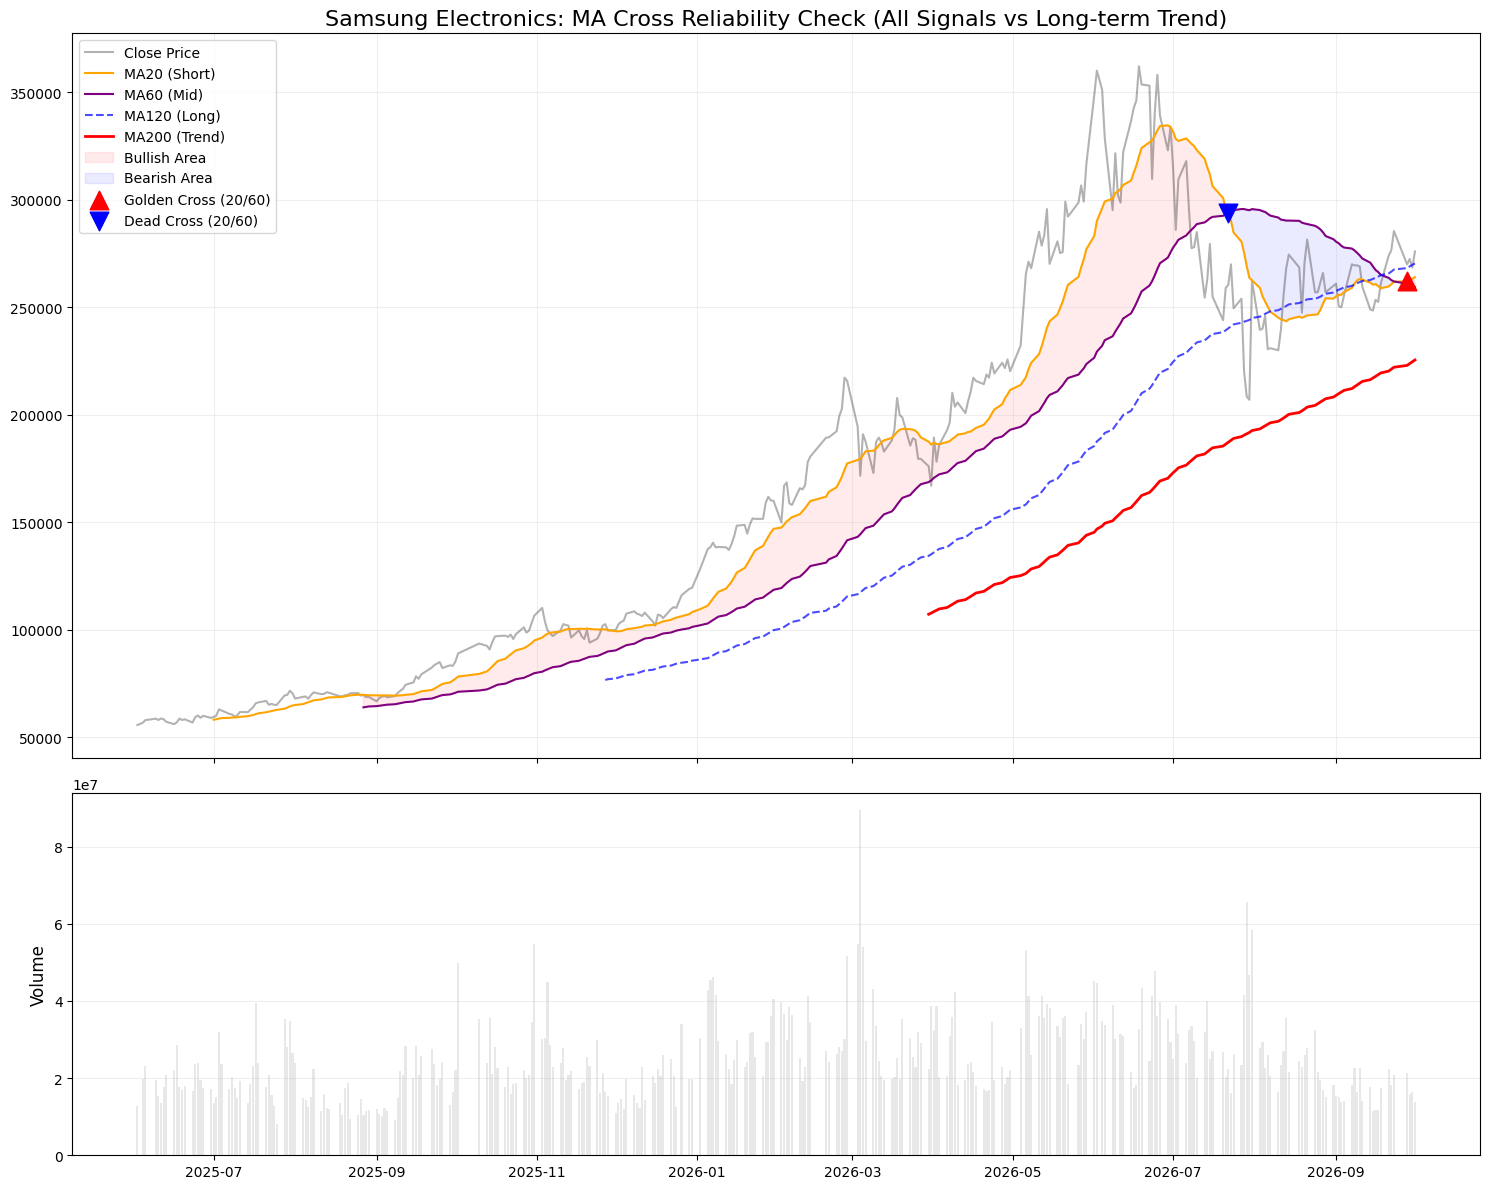

In [ ]:
import matplotlib.pyplot as plt

# 1. 원본 데이터(df)에서 모든 이동평균선 계산
df['MA20'] = df['Close'].rolling(window=20).mean()
df['MA60'] = df['Close'].rolling(window=60).mean()
df['MA120'] = df['Close'].rolling(window=120).mean()
df['MA200'] = df['Close'].rolling(window=200).mean()

# 2. 전체 기간 기준 20일선과 60일선 교차 신호 추출
df['Prev_MA20'] = df['MA20'].shift(1)
df['Prev_MA60'] = df['MA60'].shift(1)
df['GC_Signal'] = (df['Prev_MA20'] < df['Prev_MA60']) & (df['MA20'] >= df['MA60'])
df['DC_Signal'] = (df['Prev_MA20'] > df['Prev_MA60']) & (df['MA20'] <= df['MA60'])

# 3. 시각화 (행을 잘라내지 않고 전체 기간 df를 그대로 사용하여 신호 누락 방지)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 12), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

# --- 상단 차트: 주가 + 4개 이동평균선 ---
ax1.plot(df.index, df['Close'], label='Close Price', color='black', alpha=0.3)
ax1.plot(df.index, df['MA20'], label='MA20 (Short)', color='orange', linewidth=1.5)
ax1.plot(df.index, df['MA60'], label='MA60 (Mid)', color='purple', linewidth=1.5)
ax1.plot(df.index, df['MA120'], label='MA120 (Long)', color='blue', linestyle='--', alpha=0.7)
ax1.plot(df.index, df['MA200'], label='MA200 (Trend)', color='red', linewidth=2)

# 정배열/역배열 영역 채우기
ax1.fill_between(df.index, df['MA20'], df['MA60'],
                 where=(df['MA20'] >= df['MA60']), color='red', alpha=0.08, label='Bullish Area')
ax1.fill_between(df.index, df['MA20'], df['MA60'],
                 where=(df['MA20'] < df['MA60']), color='blue', alpha=0.08, label='Bearish Area')

# 골든/데드크로스 신호 표시 (전체 기간에서 매칭)
gc_points = df[df['GC_Signal']]
dc_points = df[df['DC_Signal']]

ax1.scatter(gc_points.index, gc_points['MA20'], color='red', marker='^', s=180, label='Golden Cross (20/60)', zorder=5)
ax1.scatter(dc_points.index, dc_points['MA20'], color='blue', marker='v', s=180, label='Dead Cross (20/60)', zorder=5)

ax1.set_title("Samsung Electronics: MA Cross Reliability Check (All Signals vs Long-term Trend)", fontsize=16)
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.2)

# --- 하단 차트: 거래량 ---
ax2.bar(df.index, df['Volume'], color='lightgray', alpha=0.5, label='Volume')
ax2.set_ylabel("Volume", fontsize=12)
ax2.grid(axis='y', alpha=0.2)

plt.tight_layout()
plt.show()

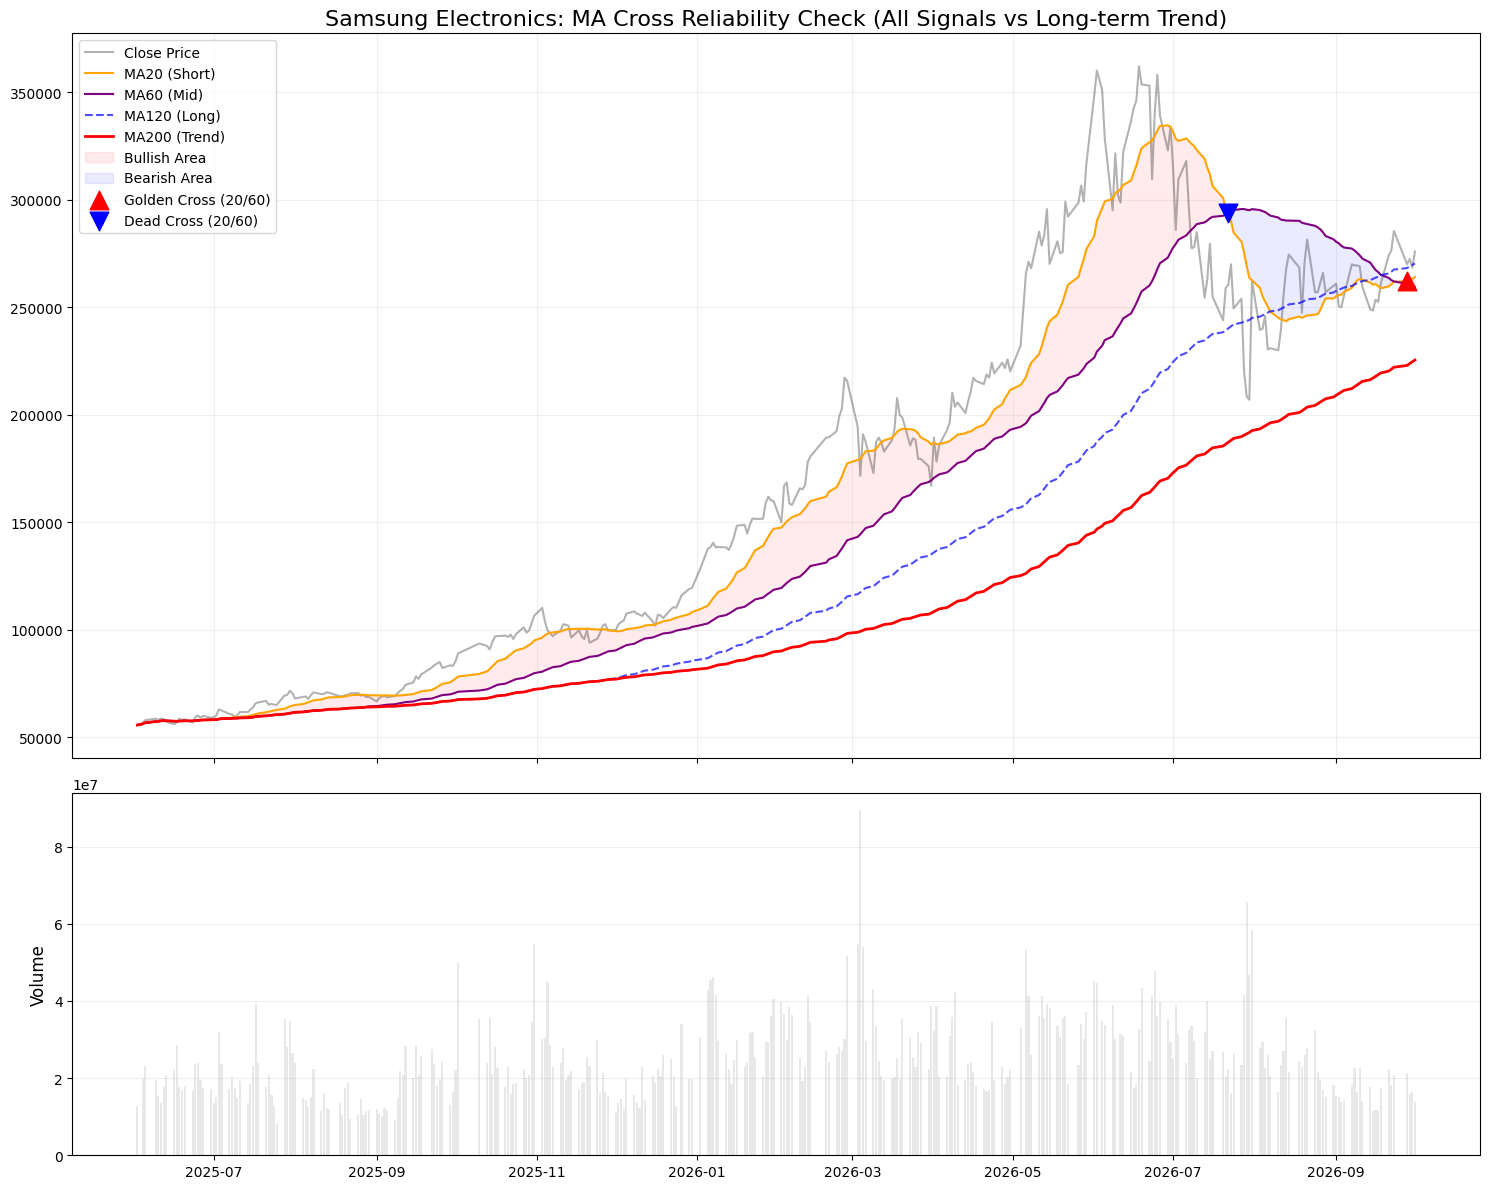

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- 1. 지표 계산 (결측치 보완 vs 엄격한 신호) ---

# [시각화용] min_periods=1을 사용하여 2025년 시작점부터 선이 끊김 없이 그려집니다.
df['MA20_plot'] = df['Close'].rolling(window=20, min_periods=1).mean()
df['MA60_plot'] = df['Close'].rolling(window=60, min_periods=1).mean()
df['MA120_plot'] = df['Close'].rolling(window=120, min_periods=1).mean()
df['MA200_plot'] = df['Close'].rolling(window=200, min_periods=1).mean()

# [신호 판정용] 데이터가 충분히 쌓여야 계산되도록 하여 2025년의 불안정한 신호를 방지합니다.
df['MA20_sig'] = df['Close'].rolling(window=20).mean()
df['MA60_sig'] = df['Close'].rolling(window=60).mean()

# 2. 전체 기간 기준 20일선과 60일선 교차 신호 추출 (엄격한 기준 사용)
df['Prev_MA20'] = df['MA20_sig'].shift(1)
df['Prev_MA60'] = df['MA60_sig'].shift(1)
df['GC_Signal'] = (df['Prev_MA20'] < df['Prev_MA60']) & (df['MA20_sig'] >= df['MA60_sig'])
df['DC_Signal'] = (df['Prev_MA20'] > df['Prev_MA60']) & (df['MA20_sig'] <= df['MA60_sig'])

# 3. 시각화
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 12), sharex=True, gridspec_kw={'height_ratios': [2, 1]})

# --- 상단 차트: 주가 + 4개 이동평균선 (결측치 제거 버전으로 시각화) ---
ax1.plot(df.index, df['Close'], label='Close Price', color='black', alpha=0.3)
ax1.plot(df.index, df['MA20_plot'], label='MA20 (Short)', color='orange', linewidth=1.5)
ax1.plot(df.index, df['MA60_plot'], label='MA60 (Mid)', color='purple', linewidth=1.5)
ax1.plot(df.index, df['MA120_plot'], label='MA120 (Long)', color='blue', linestyle='--', alpha=0.7)
ax1.plot(df.index, df['MA200_plot'], label='MA200 (Trend)', color='red', linewidth=2)

# 정배열/역배열 영역 채우기 (결측치 없는 plot용 데이터 사용)
ax1.fill_between(df.index, df['MA20_plot'], df['MA60_plot'],
                 where=(df['MA20_plot'] >= df['MA60_plot']), color='red', alpha=0.08, label='Bullish Area')
ax1.fill_between(df.index, df['MA20_plot'], df['MA60_plot'],
                 where=(df['MA20_plot'] < df['MA60_plot']), color='blue', alpha=0.08, label='Bearish Area')

# 골든/데드크로스 신호 표시 (2026년의 정확한 시점에만 표시됨)
gc_points = df[df['GC_Signal']]
dc_points = df[df['DC_Signal']]

ax1.scatter(gc_points.index, gc_points['MA20_plot'], color='red', marker='^', s=180, label='Golden Cross (20/60)', zorder=5)
ax1.scatter(dc_points.index, dc_points['MA20_plot'], color='blue', marker='v', s=180, label='Dead Cross (20/60)', zorder=5)

ax1.set_title("Samsung Electronics: MA Cross Reliability Check (All Signals vs Long-term Trend)", fontsize=16)
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.2)

# --- 하단 차트: 거래량 ---
ax2.bar(df.index, df['Volume'], color='lightgray', alpha=0.5, label='Volume')
ax2.set_ylabel("Volume", fontsize=12)
ax2.grid(axis='y', alpha=0.2)
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m')) # X축 날짜 포맷 유지

plt.tight_layout()
plt.show()